Load data from CSV

In [1]:
import matplotlib.pyplot as plt
from analysis import load_dataframe

df = load_dataframe("test_metrics.csv")
df.head()

,timestamp,client,operation,filename,size_bytes,duration_s,rate_mbps,concurrent_clients,protocol,success
0,2026-11-16T17:06:50,client1,upload,text_file,26214400,0.0091,2762.03,3,TCP,True
1,2026-11-16T17:06:50,client3,upload,text_file,26214400,0.0092,2731.10,3,TCP,True
2,2026-11-16T17:06:50,client2,upload,text_file,26214400,0.0093,2675.98,3,TCP,True
3,2026-11-16T17:06:50,client1,download,text_file,26214400,0.0053,4708.65,3,TCP,True
4,2026-11-16T17:06:50,client3,download,text_file,26214400,0.0068,3680.94,3,TCP,True


Transfer Time Vs File Size

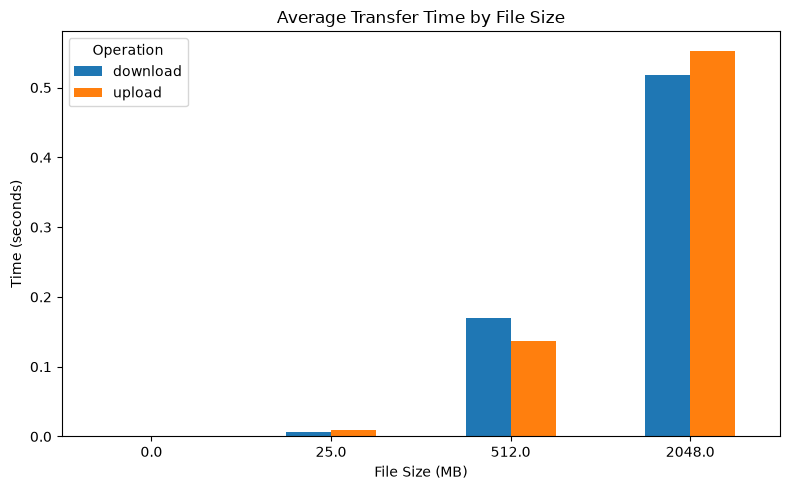

In [ ]:
# Only file transfers
transfers = df[df["operation"].isin(["upload", "download"])].copy()
transfers["size_mb"] = transfers["size_bytes"] / (1024 * 1024)

# The average time per file size, displays upload and download side by side
avg_time = transfers.groupby(["size_mb", "operation"])["duration_s"].mean().unstack()

avg_time.plot(kind="bar", figsize=(8, 5))
plt.title("Average Transfer Time by File Size")
plt.xlabel("File Size (MB)")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=0)
plt.legend(title="Operation")
plt.tight_layout()
plt.show()

Upload vs Download Speed

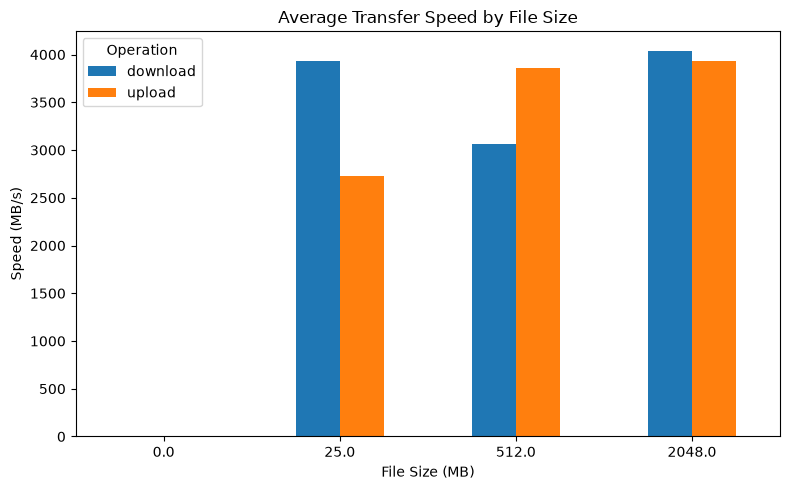

In [ ]:
#average speed per file size
avg_rate = transfers.groupby(["size_mb", "operation"])["rate_mbps"].mean().unstack()

avg_rate.plot(kind="bar", figsize=(8, 5))
plt.title("Average Transfer Speed by File Size")
plt.xlabel("File Size (MB)")
plt.ylabel("Speed (MB/s)")
plt.xticks(rotation=0)
plt.legend(title="Operation")
plt.tight_layout()
plt.show()